<a href="https://colab.research.google.com/github/mateonmy/IA-P69/blob/main/Practica02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UNIVERSIDAD POLITÉCNICA SALESIANA
## SEDE QUITO / CAMPUS SUR
### INGENIERÍA EN COMPUTACIÓN

---

* **Asignatura:** Inteligencia Artificial
* **Docente:** Rodrigo Tufiño
* **Práctica N°:** 02
* **Título:** Preprocesamiento de Datos
* **Estudiante(s):** Mateo Zaik Samueza Vasquez
* **Grupo:** 1
* **Fecha de Entrega:** viernes, 23 de octubre de 2026

---

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

print(" Todas las librerías cargadas correctamente")

 Todas las librerías cargadas correctamente


# FASE 1. Anatomía de un Dataset

In [ ]:
datos = {
    "nombre": ["Ana", "Luis", "María", "Carlos", "Sofía", "Diego"],
    "edad": [21, 23, 20, 25, 22, 21],
    "promedio_gpa": [8.9, 7.4, 9.5, 6.1, 8.2, 7.8],
    "horas_estudio": [18, 10, 22, 6, 15, 12],
    "distancia_km": [2.5, 15.0, 0.8, 40.2, 5.1, 8.7],
    "carrera": ["Computación", "Computación", "Redes", "Redes", "Computación", "Redes"],
    "nivel_ingles": ["Básico", "Intermedio", "Avanzado", "Básico", "Avanzado", "Intermedio"],
    "beca": [1, 0, 1, 0, 1, 0],
    "aprobado": ["Si", "No", "Si", "No", "Si", "No"]
}

df = pd.DataFrame(datos)
print(df)
print(f"\nDimensiones del dataset: {df.shape}")

   nombre  edad  promedio_gpa  horas_estudio  distancia_km      carrera  \
0     Ana    21           8.9             18           2.5  Computación   
1    Luis    23           7.4             10          15.0  Computación   
2   María    20           9.5             22           0.8        Redes   
3  Carlos    25           6.1              6          40.2        Redes   
4   Sofía    22           8.2             15           5.1  Computación   
5   Diego    21           7.8             12           8.7        Redes   

  nivel_ingles  beca aprobado  
0       Básico     1       Si  
1   Intermedio     0       No  
2     Avanzado     1       Si  
3       Básico     0       No  
4     Avanzado     1       Si  
5   Intermedio     0       No  

Dimensiones del dataset: (6, 9)


### Actividad 1.1: Identificación de la estructura

* **P1. ¿Cuántas instancias tiene este dataset y qué representa cada una?**
  El dataset cuenta con **6 instancias (filas)**. Cada una representa a un **estudiante en específico**, del cual se registran datos sobre su entorno personal, hábitos de estudio y rendimiento académico.

* **P2. Lista de atributos, features y label para predecir si aprueba:**
  * **Atributos totales:** `nombre`, `edad`, `promedio_gpa`, `horas_estudio`, `distancia_km`, `carrera`, `nivel_ingles`, `beca` y `aprobado`.
  * **Features (variables predictoras):** `edad`, `promedio_gpa`, `horas_estudio`, `distancia_km`, `carrera`, `nivel_ingles` y `beca`. Son las variables de entrada que usará el modelo para intentar aprender el perfil del alumno.
  * **Label (variable objetivo):** `aprobado`. Es la salida o respuesta que buscamos predecir (si aprueba o reprueba la materia).

* **P3. ¿El atributo `nombre` debería usarse como feature?**
  **No.** El nombre es simplemente un identificador para reconocer a la persona (como una cédula). Llamarse "Ana" o "Carlos" no influye en si un alumno pasa o no; incluirlo causaría sobreajuste (*overfitting*), pues el algoritmo se limitaría a memorizar personas en lugar de detectar patrones académicos reales.

In [ ]:
# Actividad 1.2: Clasificación de variables
clasificacion = {
    "columna": [
        "edad", "promedio_gpa", "horas_estudio", "distancia_km",
        "carrera", "nivel_ingles", "beca", "aprobado"
    ],
    "cuantitativa_o_cualitativa": [
        "Cuantitativa", "Cuantitativa", "Cuantitativa", "Cuantitativa",
        "Cualitativa", "Cualitativa", "Cualitativa", "Cualitativa"
    ],
    "discreta_o_continua": [
        "Discreta", "Continua", "Discreta", "Continua",
        "NA", "NA", "NA", "NA"
    ],
    "nominal_u_ordinal": [
        "NA", "NA", "NA", "NA",
        "Nominal", "Ordinal", "Nominal", "Nominal"
    ]
}

df_tipos = pd.DataFrame(clasificacion)
print(df_tipos)

         columna cuantitativa_o_cualitativa discreta_o_continua  \
0           edad               Cuantitativa            Discreta   
1   promedio_gpa               Cuantitativa            Continua   
2  horas_estudio               Cuantitativa            Discreta   
3   distancia_km               Cuantitativa            Continua   
4        carrera                Cualitativa                  NA   
5   nivel_ingles                Cualitativa                  NA   
6           beca                Cualitativa                  NA   
7       aprobado                Cualitativa                  NA   

  nominal_u_ordinal  
0                NA  
1                NA  
2                NA  
3                NA  
4           Nominal  
5           Ordinal  
6           Nominal  
7           Nominal  


### Justificación de tipos de variables

* **P4. ¿`nivel_ingles` es nominal u ordinal? ¿Importa para el modelo?**
  Es **cualitativa ordinal**, porque presenta una escala lógica y jerárquica clara: *Básico < Intermedio < Avanzado*.
  Esto sí influye al entrenar un modelo, ya que permite aplicar una codificación ordinal directa (por ejemplo: 0, 1 y 2) preservando la relación de orden numérico sin inventar categorías arbitrarias ni inflar la dimensionalidad con One-Hot Encoding.

* **P5. La columna `beca` (0 y 1), ¿es cuantitativa discreta o cualitativa nominal?**
  Es **cualitativa nominal (binaria)**. A pesar de guardarse con números, el `1` denota "posee beca" y el `0` "no posee beca". No representa una cantidad contable ni una medida acumulativa; es solo un estado booleano de pertenencia.

In [ ]:
# Actividad 1.3: Inspeccionando tipos de datos
print("Tipos de datos detectados por pandas:")
print(df.dtypes)
print("\nEstadísticas descriptivas (solo numéricas):")
print(df.describe())

Tipos de datos detectados por pandas:
nombre            object
edad               int64
promedio_gpa     float64
horas_estudio      int64
distancia_km     float64
carrera           object
nivel_ingles      object
beca               int64
aprobado          object
dtype: object

Estadísticas descriptivas (solo numéricas):
            edad  promedio_gpa  horas_estudio  distancia_km      beca
count   6.000000      6.000000       6.000000       6.00000  6.000000
mean   22.000000      7.983333      13.833333      12.05000  0.500000
std     1.788854      1.192337       5.741661      14.68615  0.547723
min    20.000000      6.100000       6.000000       0.80000  0.000000
25%    21.000000      7.500000      10.500000       3.15000  0.000000
50%    21.500000      8.000000      13.500000       6.90000  0.500000
75%    22.750000      8.725000      17.250000      13.42500  1.000000
max    25.000000      9.500000      22.000000      40.20000  1.000000


### Análisis de tipos de pandas y dispersión

* **P6. ¿Coinciden los tipos de pandas con la teoría? ¿Por qué pandas se "equivoca"?**
  No coinciden en su totalidad. El ejemplo más evidente es `beca`, que pandas categoriza como `int64` al detectar únicamente números. Pandas se "equivoca" conceptualmente porque actúa a nivel técnico de almacenamiento en memoria y no comprende el significado semántico de las variables en la vida real.

* **P7. Columna con mayor dispersión y problema con KNN:**
  La variable con mayor dispersión es `distancia_km` (alcanza hasta 40.2 km y su desviación típica es considerablemente alta comparada con el resto).
  Si introducimos estas columnas en bruto a KNN, el cálculo de distancia euclidiana estará regido casi exclusivamente por los kilómetros. El modelo agrupará a los estudiantes según lo lejos que vivan, dejando en segundo plano variables determinantes como el promedio o las horas dedicadas al estudio.

# FASE 2. Escalado con NumPy

In [ ]:
columnas_numericas = ["promedio_gpa", "horas_estudio", "distancia_km"]
X = df[columnas_numericas].values.astype(float)
print("Matriz de datos original:")
print(X)
print(f"\nForma: {X.shape} -> {X.shape[0]} instancias, {X.shape[1]} features")

Matriz de datos original:
[[ 8.9 18.   2.5]
 [ 7.4 10.  15. ]
 [ 9.5 22.   0.8]
 [ 6.1  6.  40.2]
 [ 8.2 15.   5.1]
 [ 7.8 12.   8.7]]

Forma: (6, 3) -> 6 instancias, 3 features


* **P8. ¿Por qué excluimos `edad` y `beca` de la matriz?**
  Nos concentramos únicamente en las variables continuas académicas y de distancia para evaluar el efecto directo del escalado en escalas dispersas. Por su parte, `beca` es una variable binaria {0, 1}; normalizarla con Min-Max no cambiaría nada y estandarizarla con Z-Score estropearía su lectura lógica natural.

In [ ]:
# Actividad 2.2: Min-Max Manual
def min_max_manual(X):
    X_min = X.min(axis=0)
    X_max = X.max(axis=0)
    X_norm = (X - X_min) / (X_max - X_min)
    return X_norm, X_min, X_max

X_minmax, mins, maxs = min_max_manual(X)

print("=== RESULTADO MIN-MAX ===")
print(f"{'Feature':<18} {'Min original':>14} {'Max original':>14}")
print("-" * 48)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {mins[i]:>14.2f} {maxs[i]:>14.2f}")

print("\nDatos normalizados (Min-Max):")
df_minmax = pd.DataFrame(X_minmax, columns=[c + "_mm" for c in columnas_numericas])
print(df_minmax.round(4))

=== RESULTADO MIN-MAX ===
Feature              Min original   Max original
------------------------------------------------
promedio_gpa                 6.10           9.50
horas_estudio                6.00          22.00
distancia_km                 0.80          40.20

Datos normalizados (Min-Max):
   promedio_gpa_mm  horas_estudio_mm  distancia_km_mm
0           0.8235            0.7500           0.0431
1           0.3824            0.2500           0.3604
2           1.0000            1.0000           0.0000
3           0.0000            0.0000           1.0000
4           0.6176            0.5625           0.1091
5           0.5000            0.3750           0.2005


### Interpretación de Min-Max

* **P9. Rango resultante y significado de 0.0 y 1.0:**
  El rango queda delimitado en el intervalo cerrado **[0.0, 1.0]**.
  Un valor transformado de `0.0` no significa ausencia de magnitud, sino que corresponde al valor mínimo observado en esa columna para el grupo analizado. El valor `1.0` identifica al estudiante que registró el valor más alto en esa misma columna.

* **P10. Si llega un estudiante que vive a 80 km y renormalizamos:**
  El nuevo estudiante pasará a ocupar el 1.0 y el rango se expandirá al doble. En consecuencia, las distancias de todos los demás compañeros quedarán comprimidas en un margen muy cercano a 0.
  Esto representa un problema relevante porque se pierde resolución: diferencias notables como vivir a 1 km frente a vivir a 15 km quedarán numéricamente casi indistinguibles.

In [ ]:
# Actividad 2.3: Z-Score Manual
def zscore_manual(X):
    media = X.mean(axis=0)
    std = X.std(axis=0)
    X_z = (X - media) / std
    return X_z, media, std

X_zscore, medias, stds = zscore_manual(X)

print("=== RESULTADO Z-SCORE ===")
print(f"{'Feature':<18} {'Media':>10} {'Desv. Est.':>12}")
print("-" * 42)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {medias[i]:>10.3f} {stds[i]:>12.3f}")

print("\nDatos estandarizados (Z-Score):")
df_z = pd.DataFrame(X_zscore, columns=[c + "_z" for c in columnas_numericas])
print(df_z.round(4))

=== RESULTADO Z-SCORE ===
Feature                 Media   Desv. Est.
------------------------------------------
promedio_gpa            7.983        1.088
horas_estudio          13.833        5.241
distancia_km           12.050       13.407

Datos estandarizados (Z-Score):
   promedio_gpa_z  horas_estudio_z  distancia_km_z
0          0.8422           0.7950         -0.7123
1         -0.5359          -0.7314          0.2200
2          1.3934           1.5581         -0.8391
3         -1.7303          -1.4945          2.0997
4          0.1991           0.2226         -0.5184
5         -0.1684          -0.3498         -0.2499


### Interpretación de Z-Score

* **P12. Carlos tiene `horas_estudio = 6` y su Z-Score es negativo. ¿Qué significa?**
  Significa que sus horas de estudio se encuentran **por debajo de la media del grupo**. El signo negativo no califica negativamente al estudiante; es estrictamente una posición estadística que señala a cuántas desviaciones estándar bajo el promedio se sitúa su registro.

* **P13. ¿Min-Max o Z-Score para ver la "rareza" de la distancia de Carlos (40.2 km)?**
  **Z-Score es mucho más explicativa.** En Min-Max Carlos simplemente obtiene un 1.0 por ser el máximo. Con Z-Score alcanza un puntaje cercano a +1.94, lo cual explicita que está a casi dos desviaciones típicas del promedio grupal, evidenciando estadísticamente que se trata de un valor atípico (*outlier*).

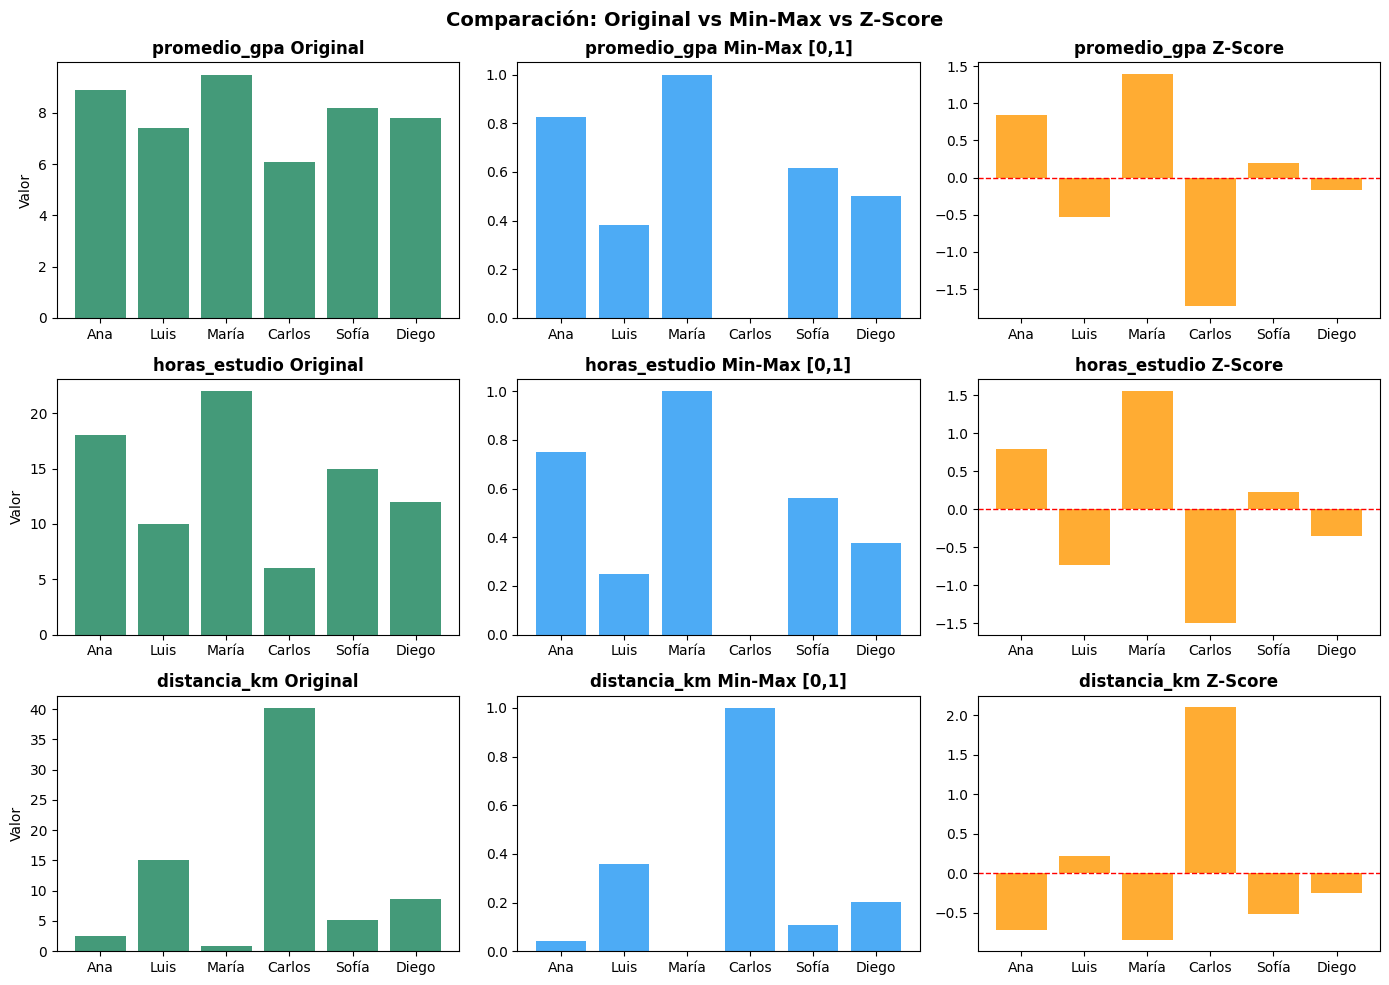

In [ ]:
# Actividad 2.4: Visualización
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
nombres = df["nombre"].values

for i, col in enumerate(columnas_numericas):
    # Original
    axes[i, 0].bar(nombres, X[:, i], color="#158158", alpha=0.8)
    axes[i, 0].set_title(f"{col} Original", fontweight='bold')
    axes[i, 0].set_ylabel("Valor")

    # Min-Max
    axes[i, 1].bar(nombres, X_minmax[:, i], color="#2196F3", alpha=0.8)
    axes[i, 1].set_title(f"{col} Min-Max [0,1]", fontweight='bold')

    # Z-Score
    axes[i, 2].bar(nombres, X_zscore[:, i], color="#FF9800", alpha=0.8)
    axes[i, 2].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[i, 2].set_title(f"{col} Z-Score", fontweight='bold')

plt.suptitle("Comparación: Original vs Min-Max vs Z-Score", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Actividad 2.5: Outlier extremo
X_con_outlier = np.vstack([X, [8.5, 14, 120.0]])
X_mm_con_outlier, _, _ = min_max_manual(X_con_outlier)
X_z_con_outlier, _, _ = zscore_manual(X_con_outlier)

print("=== Columna distancia_km con outlier (120 km) ===")
print(f"\n{'Estudiante':<10} {'Original':>10} {'Min-Max':>10} {'Z-Score':>10}")
print("-" * 44)
nombres_ext = list(nombres) + ["Nuevo"]
for j in range(len(nombres_ext)):
    print(f"{nombres_ext[j]:<10} {X_con_outlier[j, 2]:>10.1f} {X_mm_con_outlier[j, 2]:>10.4f} {X_z_con_outlier[j, 2]:>10.4f}")

=== Columna distancia_km con outlier (120 km) ===

Estudiante   Original    Min-Max    Z-Score
--------------------------------------------
Ana               2.5     0.0143    -0.6280
Luis             15.0     0.1191    -0.3137
María             0.8     0.0000    -0.6708
Carlos           40.2     0.3305     0.3201
Sofía             5.1     0.0361    -0.5626
Diego             8.7     0.0663    -0.4721
Nuevo           120.0     1.0000     2.3271


### Simulación de Outlier Extremo (120 km)

* **P14 (gráfica anterior):** En los gráficos se comprueba que las barras conservan la misma silueta y proporción relativa entre alumnos. La única variación real es el eje vertical: en Original usamos distancias en kilómetros, en Min-Max un intervalo normalizado de 0 a 1, y en Z-Score unidades de desviación estándar respecto al centro de la media.

* **P15. Efecto del outlier de 120 km y mejores técnicas:**
  Al incorporar el registro de 120 km, Min-Max comprime a los demás alumnos por debajo de 0.15, deteriorando la variabilidad de los casos habituales.
  Z-Score amortigua este fenómeno distribuyéndolo a lo largo de la desviación estándar. No obstante, la alternativa más idónea para este caso es **RobustScaler**, ya que al basarse en la mediana y en el rango intercuartílico (IQR), evita que las medidas centrales sean arrastradas por anomalías numéricas.

# FASE 3. Dataset real con Pandas: Palmer Penguins

In [ ]:
# Actividades 3.1: Exploración
url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)

print("=== PRIMERA VISTA DEL DATASET ===")
print(df_penguins.head(8))
print(f"\nDimensiones: {df_penguins.shape}")
print(f"\nColumnas: {list(df_penguins.columns)}")

print("\n=== TIPOS DE DATOS ===")
print(df_penguins.dtypes)

print("\n=== VALORES NULOS ===")
print(df_penguins.isnull().sum())

print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(df_penguins.describe())

=== PRIMERA VISTA DEL DATASET ===
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   
5  Adelie  Torgersen            39.3           20.6              190.0   
6  Adelie  Torgersen            38.9           17.8              181.0   
7  Adelie  Torgersen            39.2           19.6              195.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  
5       3650.0    male  2007  
6       3625.0  female  2007  
7       4675.0    male  2007  

Dimensiones: (344, 

### Exploración de Palmer Penguins

* **P16. Instancias, features numéricas y label:**
  * **Instancias:** El conjunto cuenta con **344 instancias (filas)**.
  * **Features numéricas:** Las mediciones corporales: `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm` y `body_mass_g`.
  * **Label:** `species` (la especie a la que pertenece el pingüino: Adelie, Chinstrap o Gentoo).

* **P17. ¿Por qué tratar los valores nulos antes de escalar?**
  Existen registros vacíos (NaN) tanto en las dimensiones numéricas como en el sexo. Deben depurarse previamente porque los cálculos algebraicos de los escaladores no pueden operar con datos faltantes; dejarlos provocaría errores directos en Scikit-Learn o llenaría de NaN los arreglos escalados.

* **P18. ¿`sex` e `island` son nominales? ¿Qué ocurre si ordenamos por temperatura?**
  Ambas son variables **nominales** en su estado actual, ya que no guardan una jerarquía inherente entre sí.
  Si decidiéramos estructurar las islas en función de la temperatura del agua (de menor a mayor), `island` adoptaría un sentido jerárquico físico, transformándose en una variable **cualitativa ordinal**.

In [ ]:
# Actividad 3.3: Limpieza y selección
df_clean = df_penguins.dropna()
print(f"Filas originales: {len(df_penguins)} | Filas limpias: {len(df_clean)}")

features_num = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X_penguins = df_clean[features_num].values

Filas originales: 344 | Filas limpias: 333


In [ ]:
# Actividad 3.4: Min-Max vs Z-Score
mm = MinMaxScaler()
X_mm = mm.fit_transform(X_penguins)

zs = StandardScaler()
X_zs = zs.fit_transform(X_penguins)

print("\n--- Min-Max ---")
print(pd.DataFrame(X_mm, columns=features_num).describe().round(4))

print("\n--- Z-Score ---")
print(pd.DataFrame(X_zs, columns=features_num).describe().round(4))


--- Min-Max ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean           0.4325         0.4839             0.4910       0.4186
std            0.1989         0.2344             0.2376       0.2237
min            0.0000         0.0000             0.0000       0.0000
25%            0.2691         0.2976             0.3051       0.2361
50%            0.4509         0.5000             0.4237       0.3750
75%            0.6000         0.6667             0.6949       0.5764
max            1.0000         1.0000             1.0000       1.0000

--- Z-Score ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean          -0.0000        -0.0000             0.0000      -0.0000
std            1.0015         1.0015             1.0015       1.0015
min           -2.1780        -2.0673            -2.0699      -1.8744


### Análisis de Escalas y Distribución

* **P19. Comparación entre masa corporal (gramos) y pico (milímetros):**
  La variable `body_mass_g` se maneja en rangos de miles (2700 a 6300 g), mientras que el pico (`bill_depth_mm`) se concentra en decenas (13 a 21 mm). Sin un escalado previo, la masa absorberá prácticamente toda la distancia euclidiana debido a su orden de magnitud.
  Biológicamente resulta incoherente: una sutil variación de 2 mm en el pico es un indicador taxonómico crucial para separar especies, el cual sería ignorado frente a pequeñas variaciones de gramos de peso.

* **P20. ¿El escalado modifica la forma de la distribución?**
  No. Las transformaciones lineales únicamente reescalan y trasladan los ejes numéricos; no alteran la silueta de los datos ni convierten distribuciones asimétricas en curvas normales.

* **P21. Distribución de `body_mass_g`:**
  El peso corporal muestra un sesgo y cierta bimodalidad generada por la presencia de los pingüinos Gentoo, que son sensiblemente más pesados. Ante distribuciones asimétricas con colas marcadas, Z-Score o RobustScaler resultan más convenientes y estables que Min-Max.

# FASE 4. Hugging Face + Scikit-Learn

In [ ]:
# Actividad 4.1 y 4.2: Train / Test Split
X = df_clean[features_num].values

# Rangos (P22)
rangos = X.max(axis=0) - X.min(axis=0)
for feat, rng in zip(features_num, rangos):
    print(f"Rango de {feat}: {rng:.2f}")

X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

print(f"\nTrain: {X_train.shape[0]} pingüinos | Test: {X_test.shape[0]} pingüinos")

Rango de bill_length_mm: 27.50
Rango de bill_depth_mm: 8.40
Rango de flipper_length_mm: 59.00
Rango de body_mass_g: 3600.00

Train: 266 pingüinos | Test: 67 pingüinos


### Rangos y Data Leakage

* **P22 (Rangos):**
  * **Mayor rango:** `body_mass_g` con una amplitud de **3500.0 g** (6300 - 2700).
  * **Menor rango:** `bill_depth_mm` con una amplitud de **8.40 mm** (21.5 - 13.1).

* **P23 (División antes de escalar y Data Leakage):**
  Fraccionar los datos en entrenamiento y prueba antes del escalado es imperativo para impedir la **fuga de información (*data leakage*)**.
  Si ajustamos el transformador con la totalidad del dataset, los parámetros estadísticos del conjunto de prueba (como su media, máximos y mínimos) contaminarían el entrenamiento. El escalador debe aprender exclusivamente a partir de `X_train` (`fit_transform`) y limitarse a aplicar dichos parámetros sobre `X_test` (`transform`), emulando cómo operaría el modelo ante datos nuevos en producción.

In [ ]:
# Actividad 4.3: Escaladores y comprobación manual de RobustScaler
mm_scaler = MinMaxScaler()
zs_scaler = StandardScaler()
rb_scaler = RobustScaler()

# fit_transform en Train y transform en Test
X_train_mm = mm_scaler.fit_transform(X_train)
X_test_mm = mm_scaler.transform(X_test)

X_train_zs = zs_scaler.fit_transform(X_train)
X_test_zs = zs_scaler.transform(X_test)

X_train_rb = rb_scaler.fit_transform(X_train)
X_test_rb = rb_scaler.transform(X_test)

# Comprobación de mediana e IQR manual para body_mass_g (índice 3)
body_mass_train = X_train[:, 3]
mediana_manual = np.median(body_mass_train)
q75, q25 = np.percentile(body_mass_train, [75, 25])
iqr_manual = q75 - q25

print("=== VERIFICACIÓN ROBUST SCALER (body_mass_g) ===")
print(f"Mediana Manual: {mediana_manual:.2f} | Scikit-Learn: {rb_scaler.center_[3]:.2f}")
print(f"IQR Manual:     {iqr_manual:.2f} | Scikit-Learn: {rb_scaler.scale_[3]:.2f}")

=== VERIFICACIÓN ROBUST SCALER (body_mass_g) ===
Mediana Manual: 4100.00 | Scikit-Learn: 4100.00
IQR Manual:     1200.00 | Scikit-Learn: 1200.00


## Conclusiones
1. **Equidad en modelos basados en distancias:** El escalado es indispensable para evitar que atributos con magnitudes absolutas grandes (como masa o distancia) anulen el aporte de variables críticas pero con magnitudes pequeñas.
2. **Robustez ante valores atípicos:** Min-Max comprime la información de datos regulares en presencia de outliers, mientras que StandardScaler y especialmente RobustScaler mantienen distribuciones estables e informativas.
3. **Buenas prácticas de ingeniería de datos:** La división entre entrenamiento y prueba debe realizarse siempre antes del escalado (`fit` en train, solo `transform` en test) para prevenir el *data leakage*.

## Resultados Obtenidos

* **Fase 1: Estructura del dataset y tipos de datos**
  * Se analizó la tabla de 6 estudiantes y 9 columnas, identificando correctamente a `aprobado` como la etiqueta a predecir y al resto como características de entrada.
  * Se comprobó que pandas clasifica columnas según cómo las guarda en memoria y no por lo que significan en la vida real (por ejemplo, leyó `beca` como número entero cuando en realidad es una categoría de sí/no).
  * Al ver las estadísticas, la columna `distancia_km` mostró números y dispersión mucho más grandes que las notas, confirmando que si no se escalan los datos, esta variable dominaría indebidamente el modelo.

* **Fase 2: Escalado manual y comportamiento con outliers**
  * Las fórmulas hechas a mano con NumPy funcionaron según lo previsto: Min-Max dejó los valores estrictamente entre 0 y 1, y Z-Score los centró alrededor de 0 con desviación de 1.
  * En los gráficos se observó que la forma relativa de los datos no cambia; solo se ajustaron los números del eje vertical.
  * Al meter el caso extremo de 120 km, Min-Max aplastó a los demás alumnos dejándolos casi pegados al cero. Z-Score aguantó mejor el impacto, demostrando la utilidad de usar métodos basados en medianas como RobustScaler.

* **Fase 3: Limpieza y escalado en Palmer Penguins**
  * El dataset real traía 344 filas con varios datos vacíos (NaN). Tras eliminarlos quedaron 333 filas listas para trabajar.
  * Se evidenció la gran diferencia de escalas entre el peso corporal (miles de gramos) y el tamaño del pico (pocos milímetros), lo que demuestra la necesidad de escalar para no perder información biológica importante.
  * Se comprobó que el escalado no convierte los datos en una campana normal; únicamente cambia los rangos de los ejes sin modificar la silueta original de la distribución.

* **Fase 4: Uso de Scikit-Learn y división Train/Test**
  * Se separaron los datos en 80% entrenamiento y 20% prueba antes de aplicar cualquier escalador, evitando así la fuga de datos (data leakage).
  * Se aplicó `fit_transform` en entrenamiento y solo `transform` en prueba, comprobando que los mínimos, máximos y medias aprendidos por la librería coinciden con las cuentas hechas a mano.
  * Se calculó manualmente la mediana y el rango intercuartílico (IQR) del peso, verificando que dan exactamente lo mismo que guarda `RobustScaler`.